# WorkShop1
## DNNs en datos tabulares

**Parte 2) Modelo de clasificación del precio de viviendas**

Problema de **clasificación binaria**: predecir si una vivienda está por encima de la mediana de precios (`AboveMedianPrice`).

## Objetivos
- Explorar y validar datos tabulares.
- Separar entrenamiento, validación y prueba sin fuga de información (*data leakage*).
- Escalar variables numéricas.
- Construir una red densa con ReLU y salida sigmoide.
- Comprender pérdida, optimizador, épocas, mini-lotes y semillas.
- Interpretar curvas de aprendizaje y diagnosticar subajuste/sobreajuste.
- Comparar anchura, profundidad, y medidas de *dropout* y regularización L2.
- Usar Métricas: matriz de confusión, precisión, exhaustividad, F1, ROC-AUC y Average Precision.
- Examinar importancia por permutación.

**Archivo esperado:** `housepricedata.csv`, en esta misma carpeta. El CSV debe contener exactamente las variables listadas abajo (puede contener columnas adicionales; el notebook las ignorará).

## 1. Variables y definición del problema

**Entradas (10):** `LotArea`, `OverallQual`, `OverallCond`, `TotalBsmtSF`, `FullBath`, `HalfBath`, `BedroomAbvGr`, `TotRmsAbvGrd`, `Fireplaces`, `GarageArea`.

**Objetivo (1):** `AboveMedianPrice`, codificado como 0/1.

> Nota metodológica: este notebook asume que `AboveMedianPrice` ya viene calculada en el CSV. Para evitar ambigüedad, `1` significa vivienda por encima de la mediana y `0` significa vivienda en la mediana o por debajo. Si la etiqueta fue calculada usando el precio de todo el conjunto, úsese como ejercicio didáctico; en un escenario real, defina cuidadosamente la mediana usando únicamente los datos de entrenamiento cuando corresponda.

In [1]:
from pathlib import Path
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42 # es una convencion muy usada
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

DATA_PATH = Path("housepricedata.csv")
FEATURES = [
    "LotArea", "OverallQual", "OverallCond", "TotalBsmtSF", "FullBath",
    "HalfBath", "BedroomAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageArea"
]
TARGET = "AboveMedianPrice"

print("Carpeta de trabajo:", Path.cwd())
print("CSV esperado:", DATA_PATH.resolve())

Fontconfig warning: ignoring UTF-8: not a valid region tag
Matplotlib is building the font cache; this may take a moment.


Carpeta de trabajo: /Users/unalmed/Downloads/Deep Learning
CSV esperado: /Users/unalmed/Downloads/Deep Learning/housepricedata.csv


## 2. Cargar y validar el CSV
Si el archivo está en otra ubicación, cambie `DATA_PATH` en la celda anterior. No se genera ni se inventa un conjunto de datos: el análisis requiere su CSV real.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró {DATA_PATH.resolve()}. "
        "Copie housepricedata.csv en la misma carpeta del notebook o ajuste DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (1460, 11)


,LotArea,OverallQual,OverallCond,TotalBsmtSF,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageArea,AboveMedianPrice
0,8450,7,5,856,2,1,3,8,0,548,1
1,9600,6,8,1262,2,0,3,6,1,460,1
2,11250,7,5,920,2,1,3,6,1,608,1
3,9550,7,5,756,1,0,3,7,1,642,0
4,14260,8,5,1145,2,1,4,9,1,836,1


In [3]:
required = FEATURES + [TARGET]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Faltan columnas requeridas: {missing_cols}")

data = df[required].copy()
print("Tipos de datos:")
display(data.dtypes.to_frame("dtype"))
print("Valores ausentes por variable:")
display(data.isna().sum().to_frame("missing"))
print("Estadísticos descriptivos:")
display(data.describe().T)

Tipos de datos:


,dtype
LotArea,int64
OverallQual,int64
OverallCond,int64
TotalBsmtSF,int64
FullBath,int64
HalfBath,int64
BedroomAbvGr,int64
TotRmsAbvGrd,int64
Fireplaces,int64
GarageArea,int64


Valores ausentes por variable:


,missing
LotArea,0
OverallQual,0
OverallCond,0
TotalBsmtSF,0
FullBath,0
HalfBath,0
BedroomAbvGr,0
TotRmsAbvGrd,0
Fireplaces,0
GarageArea,0


Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
TotalBsmtSF,1460.0,1057.429452,438.705324,0.0,795.75,991.5,1298.25,6110.0
FullBath,1460.0,1.565068,0.550916,0.0,1.00,2.0,2.00,3.0
HalfBath,1460.0,0.382877,0.502885,0.0,0.00,0.0,1.00,2.0
BedroomAbvGr,1460.0,2.866438,0.815778,0.0,2.00,3.0,3.00,8.0
TotRmsAbvGrd,1460.0,6.517808,1.625393,2.0,5.00,6.0,7.00,14.0
Fireplaces,1460.0,0.613014,0.644666,0.0,0.00,1.0,1.00,3.0
GarageArea,1460.0,472.980137,213.804841,0.0,334.50,480.0,576.00,1418.0


In [4]:
# Convertir entradas a numéricas y revisar etiquetas
for col in FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
data = data.dropna(subset=required).copy()

labels = set(data[TARGET].unique().tolist())
if not labels.issubset({0, 1}):
    raise ValueError(f"{TARGET} debe estar codificada como 0/1; valores encontrados: {sorted(labels)}")
data[TARGET] = data[TARGET].astype("int32")

print("Filas después de quitar valores ausentes/no numéricos:", len(data))
print("Distribución de clases:")
display(data[TARGET].value_counts().sort_index().rename(index={0:"0: mediana o menos",1:"1: sobre mediana"}).to_frame("n"))
display((data[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_frame("%"))

Filas después de quitar valores ausentes/no numéricos: 1460
Distribución de clases:


,n
AboveMedianPrice,
0: mediana o menos,732
1: sobre mediana,728


,%
AboveMedianPrice,
0,50.14
1,49.86


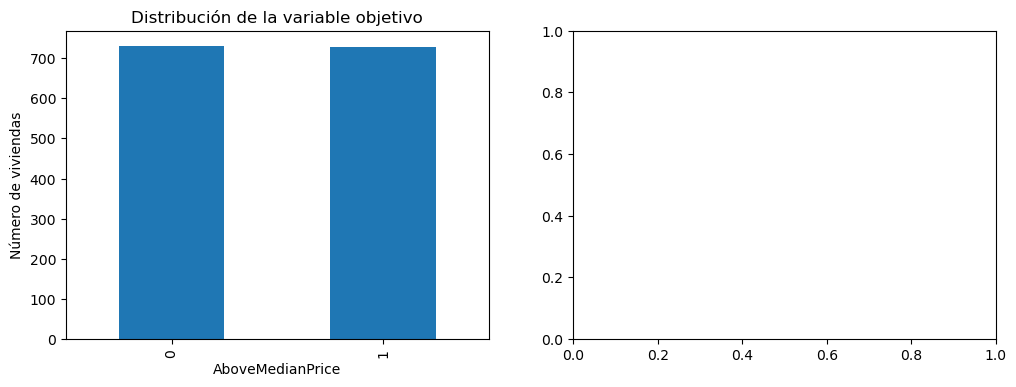

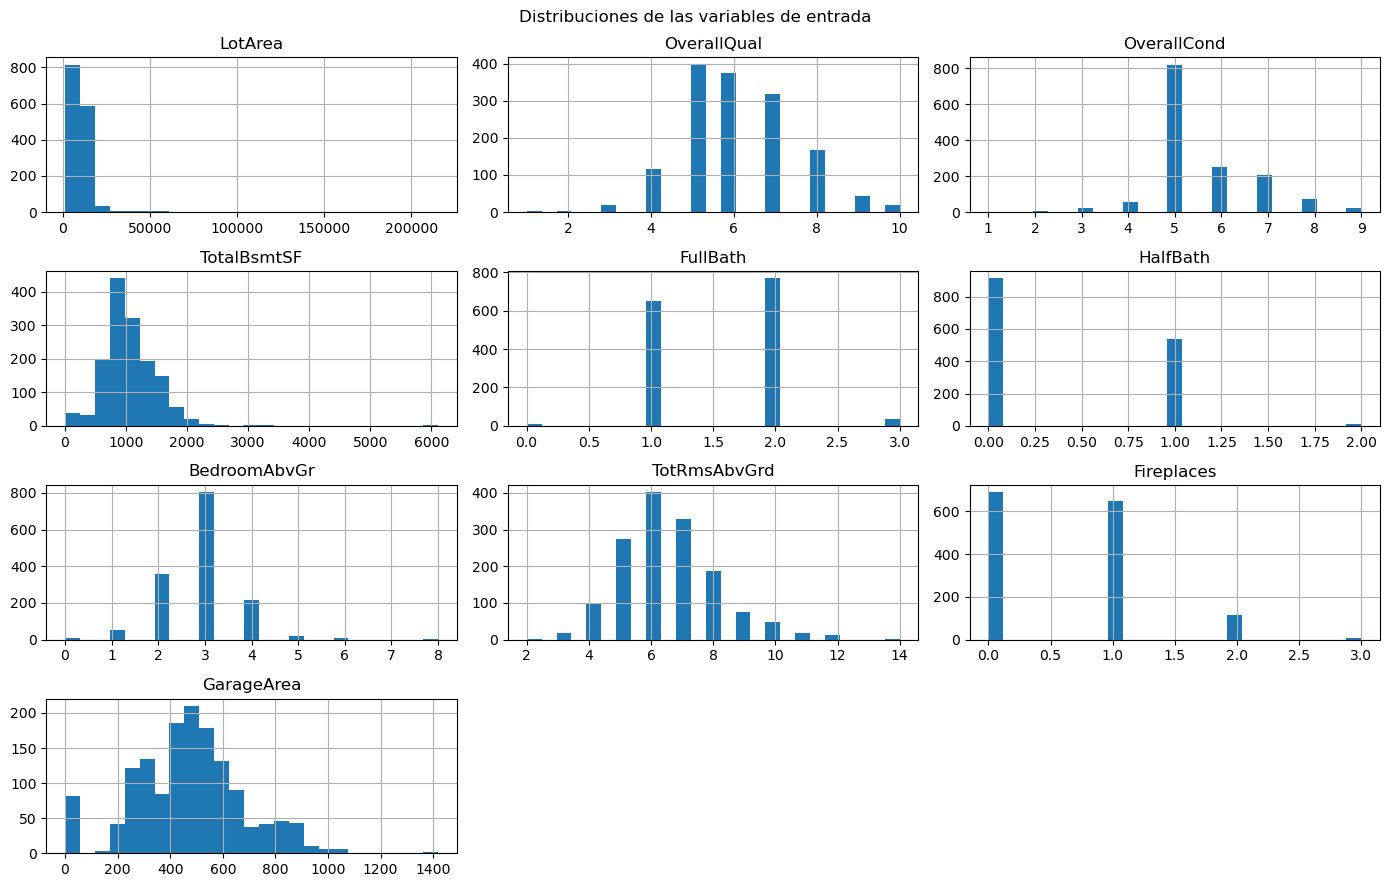

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data[TARGET].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set(title="Distribución de la variable objetivo", xlabel="AboveMedianPrice", ylabel="Número de viviendas")
data[FEATURES].hist(figsize=(14, 9), bins=25)
plt.suptitle("Distribuciones de las variables de entrada")
plt.tight_layout()
plt.show()

## 3. Particiones: Entrenamiento, validación y prueba

Se reserva primero el 20 % para prueba y luego el 20 % del conjunto restante para validación. Con ello, aproximadamente quedan **64 % entrenamiento, 16 % validación y 20 % prueba**. `stratify` conserva aproximadamente la proporción de clases.

El escalador se ajusta **solo con entrenamiento**; validación y prueba se transforman con ese mismo escalador para evitar *data leakage*.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = data[FEATURES].astype("float32")
y = data[TARGET].astype("int32")

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train_df, X_val_df, y_train, y_val = train_test_split(
    X_train_df, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_df).astype("float32")
X_val = scaler.transform(X_val_df).astype("float32")
X_test = scaler.transform(X_test_df).astype("float32")

print("Train:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Prueba:", X_test.shape, y_test.shape)
print("Rango train escalado:", X_train.min(), "a", X_train.max())

Train: (934, 10) (934,)
Validación: (234, 10) (234,)
Prueba: (292, 10) (292,)
Rango train escalado: 0.0 a 1.0


## 4. Preparar TensorFlow/Keras

En un entorno donde aún no estén instaladas las dependencias, ejecute en Terminal:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install tensorflow pandas numpy matplotlib scikit-learn jupyter
jupyter lab
```


In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices())
tf.keras.utils.set_random_seed(SEED)

TensorFlow: 2.21.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 5. Modelo base: red densa para clasificación binaria

Arquitectura de referencia: **10 entradas → 16 ReLU → 16 ReLU → 1 sigmoide**, con *dropout* entre capas. La salida sigmoide estima la probabilidad de `AboveMedianPrice = 1`.

- **Función de Pérdida para clasificación:** entropía cruzada binaria.
- **Optimizador:** Adam.
- **Métrica durante el entrenamiento:** exactitud (*accuracy*).
- `batch_size` y `epochs` son hiperparámetros.

In [8]:
def build_model(width=16, depth=2, dropout=0.0, l2_strength=0.0, learning_rate=1e-3):
    model = keras.Sequential(name=f"MLP_w{width}_d{depth}")
    model.add(layers.Input(shape=(len(FEATURES),)))
    for _ in range(depth):
        model.add(layers.Dense(
            width, activation="relu",
            kernel_regularizer=regularizers.l2(l2_strength) if l2_strength > 0 else None
        ))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                 keras.metrics.AUC(name="auc")]
    )
    return model

model = build_model(width=16, depth=2, dropout=0.30)
model.summary()

Model: "MLP_w16_d2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465 (1.82 KB)

 Trainable params: 465 (1.82 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    )
]
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150, batch_size=32,
    callbacks=callbacks, verbose=1
)

Epoch 1/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5032 - auc: 0.5294 - loss: 0.6949 - val_accuracy: 0.5000 - val_auc: 0.9189 - val_loss: 0.6804
Epoch 2/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 914us/step - accuracy: 0.4914 - auc: 0.5235 - loss: 0.6918 - val_accuracy: 0.5043 - val_auc: 0.9337 - val_loss: 0.6747
Epoch 3/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.5760 - auc: 0.6378 - loss: 0.6760 - val_accuracy: 0.5085 - val_auc: 0.9349 - val_loss: 0.6679
Epoch 4/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.5685 - auc: 0.6476 - loss: 0.6713 - val_accuracy: 0.5342 - val_auc: 0.9370 - val_loss: 0.6576
Epoch 5/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step - accuracy: 0.5921 - auc: 0.6913 - loss: 0.6605 - val_accuracy: 0.5726 - val_auc: 0.9376 - val_loss: 0.6387
Epoch 6/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 786us/step - accuracy: 0.5974 - auc: 0.7224 - loss: 0.6496 - val_accuracy: 0.6667 - val_auc: 0.9374 - val_loss: 0.6205
Epoch 7/150
30/30 ━━━━━━━━━━━━━━━━━━

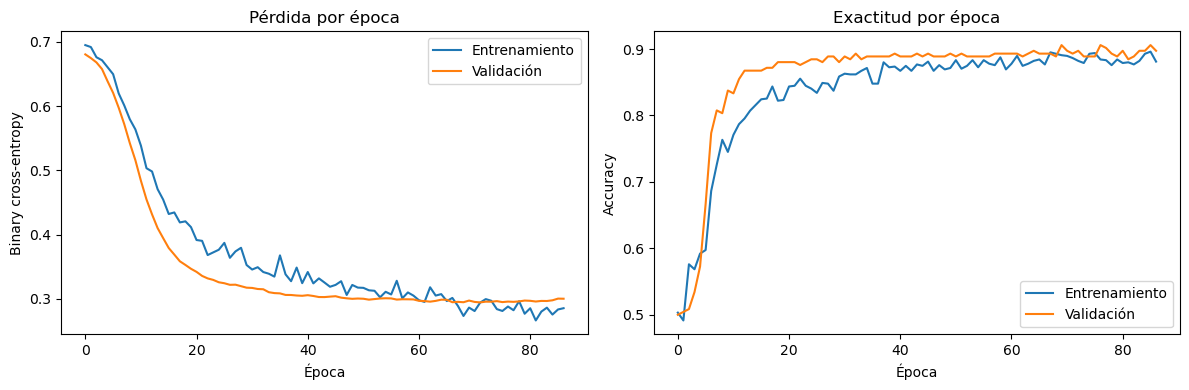

In [10]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"], label="Entrenamiento")
axes[0].plot(hist["val_loss"], label="Validación")
axes[0].set(title="Pérdida por época", xlabel="Época", ylabel="Binary cross-entropy")
axes[0].legend()
axes[1].plot(hist["accuracy"], label="Entrenamiento")
axes[1].plot(hist["val_accuracy"], label="Validación")
axes[1].set(title="Exactitud por época", xlabel="Época", ylabel="Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

### Interpretación para discusión
- **Subajuste:** pérdida alta tanto en entrenamiento como en validación.
- **Sobreajuste:** la pérdida de entrenamiento sigue bajando, pero la de validación se estanca o sube.
- La mejor época no tiene por qué ser la última; `EarlyStopping` restaura los pesos de la época con menor pérdida de validación.
- La semilla permite reproducir en parte el experimento, pero no garantiza que el modelo sea mejor.

## 6. Evaluación final en el conjunto de prueba
El conjunto de prueba se usa aquí después de entrenar y seleccionar el modelo. Evite ajustar hiperparámetros repetidamente mirando estos resultados.

Test loss: 0.2579
Test accuracy: 0.8904
Accuracy:  0.8904
Precision: 0.8851
Recall:    0.8973
F1:        0.8912
ROC-AUC:   0.9643
AvgPrec.:  0.9638

Reporte por clase:
              precision    recall  f1-score   support

           0       0.90      0.88      0.89       146
           1       0.89      0.90      0.89       146

    accuracy                           0.89       292
   macro avg       0.89      0.89      0.89       292
weighted avg       0.89      0.89      0.89       292



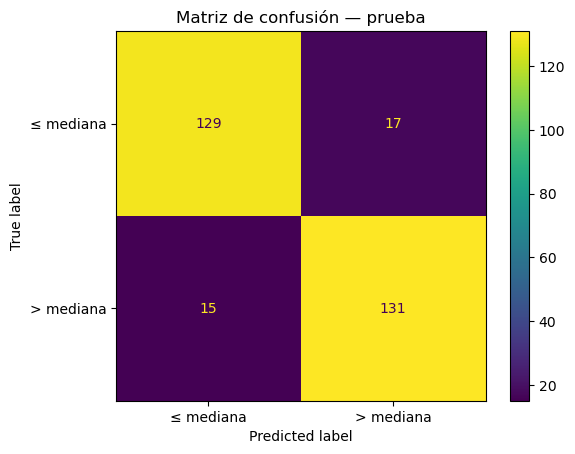

In [11]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

test_loss, test_accuracy, test_auc = model.evaluate(X_test, y_test, verbose=0)
proba_test = model.predict(X_test, verbose=0).ravel()
pred_test = (proba_test >= 0.5).astype("int32")

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Accuracy:  {accuracy_score(y_test, pred_test):.4f}")
print(f"Precision: {precision_score(y_test, pred_test, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, pred_test, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_test, pred_test, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, proba_test):.4f}")
print(f"AvgPrec.:  {average_precision_score(y_test, proba_test):.4f}")
print("\nReporte por clase:")
print(classification_report(y_test, pred_test, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["≤ mediana", "> mediana"])
plt.title("Matriz de confusión — prueba")
plt.show()

## 7. Comparar capacidad y regularización

La siguiente práctica compara configuraciones con diferente anchura, profundidad, *dropout* y regularización L2. Para que la comparación sea útil, se conserva la misma partición de datos y la misma regla de parada. Las cifras pueden variar por inicialización y versión de las bibliotecas.

In [12]:
configs = [
    {"name":"Pequeña", "width":4,  "depth":1, "dropout":0.0, "l2_strength":0.0},
    {"name":"Base",    "width":16, "depth":2, "dropout":0.3, "l2_strength":0.0},
    {"name":"Ancha",   "width":64, "depth":2, "dropout":0.0, "l2_strength":0.0},
    {"name":"Regularizada", "width":64, "depth":2, "dropout":0.3, "l2_strength":1e-3},
    {"name":"Profunda", "width":32, "depth":4, "dropout":0.2, "l2_strength":1e-4},
]
results = []
comparison_histories = {}
for cfg in configs:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(width=cfg["width"], depth=cfg["depth"],
                    dropout=cfg["dropout"], l2_strength=cfg["l2_strength"])
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=100, batch_size=32, callbacks=[
                  keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
              ], verbose=0)
    val_loss, val_acc, val_auc = m.evaluate(X_val, y_val, verbose=0)
    p = m.predict(X_test, verbose=0).ravel()
    yp = (p >= 0.5).astype(int)
    results.append({
        "modelo":cfg["name"], "anchura":cfg["width"], "capas_ocultas":cfg["depth"],
        "dropout":cfg["dropout"], "L2":cfg["l2_strength"],
        "épocas":len(h.history["loss"]), "loss_validación":val_loss,
        "accuracy_validación":val_acc, "AUC_validación":val_auc,
        "accuracy_prueba":accuracy_score(y_test, yp),
        "F1_prueba":f1_score(y_test, yp, zero_division=0)
    })
    comparison_histories[cfg["name"]] = h.history

results_df = pd.DataFrame(results).sort_values("loss_validación")
display(results_df)

,modelo,anchura,capas_ocultas,dropout,L2,épocas,loss_validación,accuracy_validación,AUC_validación,accuracy_prueba,F1_prueba
2,Ancha,64,2,0.0,0.0000,54,0.251612,0.918803,0.968259,0.897260,0.897959
3,Regularizada,64,2,0.3,0.0010,77,0.292360,0.905983,0.967529,0.897260,0.897959
1,Base,16,2,0.3,0.0000,84,0.294354,0.893162,0.961685,0.890411,0.891156
4,Profunda,32,4,0.2,0.0001,31,0.312345,0.884615,0.954124,0.880137,0.880546
0,Pequeña,4,1,0.0,0.0000,100,0.313200,0.888889,0.951019,0.873288,0.875421


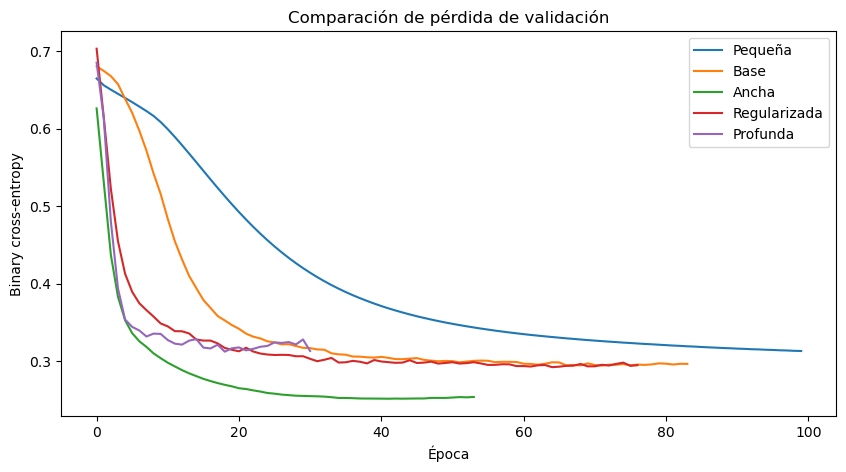

In [13]:
plt.figure(figsize=(10, 5))
for name, h in comparison_histories.items():
    plt.plot(h["val_loss"], label=name)
plt.title("Comparación de pérdida de validación")
plt.xlabel("Época")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.show()

## 8. Importancia por permutación

Se mide cuánto cae una métrica al desordenar una variable en el conjunto de validación. Una caída mayor sugiere que el modelo depende más de esa variable. Esta técnica mide dependencia predictiva del modelo, no causalidad.

,variable,caída_media_F1,desviación
4,FullBath,0.080433,0.012348
1,OverallQual,0.053003,0.004304
5,HalfBath,0.035301,0.010637
9,GarageArea,0.007204,0.010545
0,LotArea,0.004759,0.003566
8,Fireplaces,0.002424,0.006624
3,TotalBsmtSF,0.000836,0.010585
7,TotRmsAbvGrd,0.000329,0.005991
6,BedroomAbvGr,-0.004643,0.008362
2,OverallCond,-0.008016,0.006556


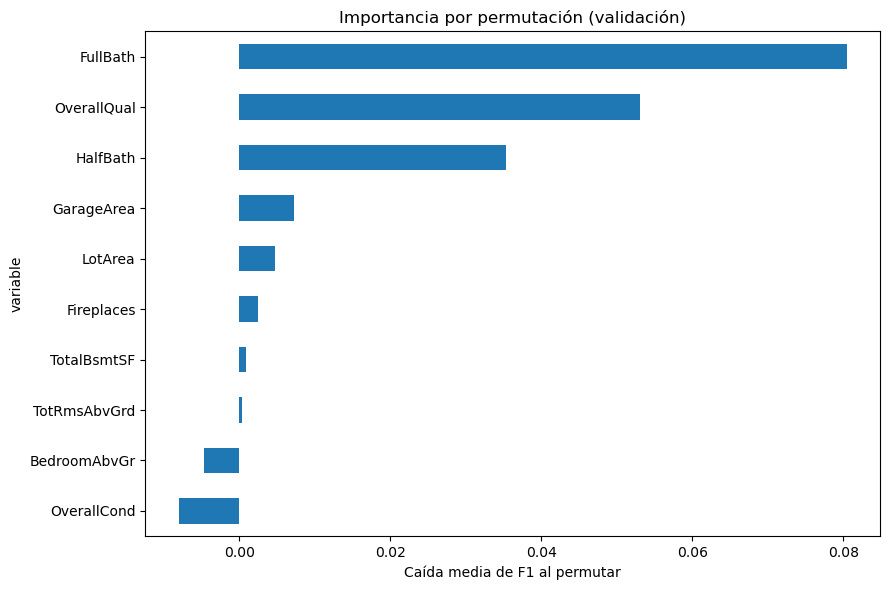

In [14]:
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin

# Adaptador para que scikit-learn use la probabilidad de Keras.
class KerasBinaryClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, keras_model):
        self.keras_model = keras_model
        self.classes_ = np.array([0, 1])
    def fit(self, X, y):
        return self
    def predict_proba(self, X):
        p = self.keras_model.predict(np.asarray(X, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1-p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

wrapped = KerasBinaryClassifier(model)
perm = permutation_importance(
    wrapped, X_val, y_val, scoring="f1", n_repeats=8, random_state=SEED
)
importance = pd.DataFrame({
    "variable": FEATURES,
    "caída_media_F1": perm.importances_mean,
    "desviación": perm.importances_std
}).sort_values("caída_media_F1", ascending=False)
display(importance)
importance.sort_values("caída_media_F1").plot(
    x="variable", y="caída_media_F1", kind="barh", legend=False, figsize=(9, 6),
    title="Importancia por permutación (validación)"
)
plt.xlabel("Caída media de F1 al permutar")
plt.tight_layout()
plt.show()

## 9. Semillas y reproducibilidad (extensión)

Una única ejecución puede ser fortuita. Para una evaluación más rigurosa, repita el entrenamiento con varias semillas y reporte media y desviación estándar de las métricas. En un curso, compare primero 3–5 semillas para limitar el tiempo de ejecución.

In [17]:
# Usando varias semillas para comparar
seed_results = []
for seed in [1, 7, 21, 42, 99]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    m_seed = build_model(width=16, depth=2, dropout=0.3)
    m_seed.fit(X_train, y_train, validation_data=(X_val, y_val),
               epochs=100, batch_size=32, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(
                   monitor="val_loss", patience=12, restore_best_weights=True)])
    p = m_seed.predict(X_test, verbose=0).ravel()
    yp = (p >= 0.5).astype(int)
    seed_results.append({
        "semilla":seed,
        "accuracy":accuracy_score(y_test, yp),
        "precision":precision_score(y_test, yp, zero_division=0),
        "recall":recall_score(y_test, yp, zero_division=0),
        "F1":f1_score(y_test, yp, zero_division=0),
        "ROC-AUC":roc_auc_score(y_test, p)
    })
seed_df = pd.DataFrame(seed_results)
display(seed_df)
display(seed_df.drop(columns="semilla").agg(["mean", "std"]).T)

,semilla,accuracy,precision,recall,F1,ROC-AUC
0,1,0.893836,0.885906,0.904110,0.894915,0.963126
1,7,0.890411,0.885135,0.897260,0.891156,0.960968
2,21,0.880137,0.877551,0.883562,0.880546,0.962376
3,42,0.890411,0.885135,0.897260,0.891156,0.964346
4,99,0.890411,0.875000,0.910959,0.892617,0.963079


,mean,std
accuracy,0.889041,0.005194
precision,0.881745,0.005084
recall,0.898630,0.010159
F1,0.890078,0.005546
ROC-AUC,0.962779,0.001236


## 10. Conclusiones

- Una red MLP aprende pesos y sesgos mediante retropropagación y un optimizador.
- Las activaciones no lineales permiten representar fronteras de decisión no lineales.
- Más neuronas/capas aumentan la capacidad, pero no garantizan mejor generalización.
- La pérdida guía el entrenamiento; las métricas evalúan el desempeño según la tarea.
- Entrenamiento, validación y prueba tienen funciones distintas.
- *Dropout*, L2 y parada temprana pueden ayudar a controlar el sobreajuste.
- La exactitud puede ocultar errores importantes; revisar matriz de confusión, F1, sensibilidad y AUC.
- La importancia por permutación describe dependencia del modelo, no efecto causal.

### Limitaciones del ejercicio
Este es un ejemplo didáctico con variables tabulares seleccionadas. El resultado depende de la calidad del CSV, la construcción de la etiqueta, la distribución de clases y la partición. La etiqueta `AboveMedianPrice` no permite recuperar el precio exacto: solo clasifica viviendas respecto al umbral de mediana definido en los datos.

**Preguntas para responder en grupo**

1. ¿Qué arquitectura presenta indicios de subajuste? ¿Qué evidencia lo respalda?
2. ¿Cuál presenta una mayor brecha entre pérdida de entrenamiento y validación?
3. ¿La arquitectura con menor pérdida de validación también tiene el mejor F1 en prueba?
4. ¿Qué cambia al introducir *dropout* y L2? ¿Qué limitaciones tiene esta comparación?
5. ¿Por qué no debemos escoger el modelo solo por la exactitud?
   